<a href="https://colab.research.google.com/github/apkh1116/strong-kheer-191531/blob/apkh/%EC%9E%A5%EA%B7%9C%ED%98%84_2_%EC%84%A0%ED%98%95_%ED%9A%8C%EA%B7%80_%EB%AA%A8%EB%8D%B8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#[문제] 목둘레로 허리둘레 예측하기

#[1단계] 데이터 수집하기 (jeans.csv)

In [ ]:
#1-1.데이터 불러오기
import pandas as pd
df = pd.read_csv('jeans.csv')
df.head()

,neck,weight,heap,waist
0,33.8,51.1,86.0,62.9
1,33.0,45.4,87.9,63.0
2,35.3,58.9,95.2,64.2
3,33.1,47.3,88.6,64.4
4,33.1,47.7,88.5,65.0


#[2단계] 데이터 전처리

In [ ]:
from re import X
#2-1. 독립변수와 종속변수 지정
import numpy as np # numpy 라이브러리 필요함
# 독립변수는 2차원 배열(행렬)이 원칙 [[ ]],  reshape가 2차원으로 재배열 해줌 //
X=df['neck'].values.reshape(-1,1)
y=df['waist'].values


In [ ]:
#2-2.훈련데이터와 테스트 데이터 분할
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,test_size=0.3, random_state=42)
#훈련데이터,테스트데이터=(값, 크기, 무작위시드)

#[3단계] 모델 생성

In [ ]:
#3-1.기계학습 유형과 알고리즘 선정
#지도학습>선형회귀모델(연속적인 수치 예측)
#3-2.모델 학습
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train, y_train) #선형회귀에서 fit은 학습시킴

LinearRegression()

In [ ]:
#3-3.회귀계수(기울기)와 절편
#y=aX+b, 언더바_ 는 선형회귀에서 쓰임
#y=2.832X -24.721
print(model.coef_, model.intercept_)

[2.83240592] -24.72124084231578


In [ ]:
#3-4.모델 성능 평가
#결정계수 의미 >> 모델이 실제 데이터를 잘 설명하고 있는지를 수치로 나타냄(0~1)
model.score(X_train, y_train)
# 0.7이상이 유의미함, 모델 성능이 나쁘지 않음

0.6981528219455009

#[4단계] 모델 평가하기

In [ ]:
#4-1.테스트 데이터를 이용한 성능 평가
#평가 결과 >>
print(model.score(X_test, y_test))

0.7125583463172804


In [ ]:
#4-2.예측 수행
predictions = model.predict(X_test)
print('예측값 :', predictions[:5])  #[:]는 0부터 끝까지( : 을 기준으로 앞부터 뒤까지)
print('테스트 결괏값 : ', y_test[:5])

예측값 : [80.07777815 77.81185342 79.51129697 84.60962763 75.54592868]
테스트 결괏값 :  [82.9 78.6 78.7 90.3 76.7]


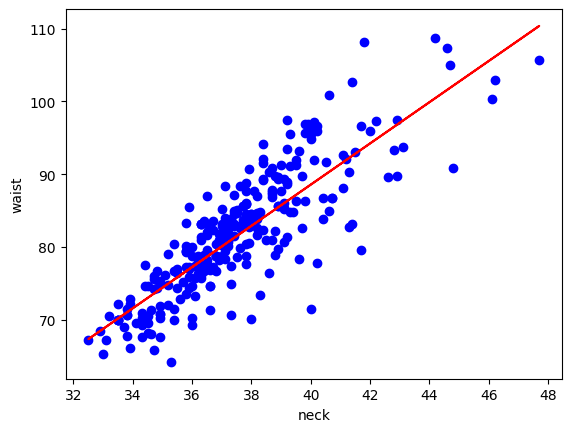

In [ ]:
#4-3.산점도(테스트 데이터)
import matplotlib.pyplot as plt
plt.scatter(X_test, y_test, color='blue')
plt.plot(X_test, predictions, color='red')
plt.xlabel('neck')
plt.ylabel('waist')
plt.show()

In [ ]:
#모델 활용하기
print('----------허리둘레 예측하기-----------')
n=float(input('당신의 목둘레는?(cm) '))
pw = model.predict([[n]])[0]
print(f'당신의 허리둘레는 {pw:.1f}입니다.')

----------허리둘레 예측하기-----------
당신의 목둘레는?(cm) 40
당신의 허리둘레는 88.6입니다.
